In [65]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii
import scipy.constants as con

data = ascii.read("/Users/harry/Downloads/data.dat", data_start=5)
lam      = np.array(data["col1"], dtype=float)  
logf     = np.array(data["col2"], dtype=float)
logf_err = np.array(data["col3"], dtype=float)

#constants
h = con.h
c = con.c
k = con.k

#initial constraints for fit parameters temp and log constant
temp_min = 100 
temp_max = 1000
a_min = -50
a_max = 0
theta_shape = np.array([[temp_min, temp_max],[a_min, a_max]])


def log_prior(theta, theta_shape):
    temp, a = theta
    logpriors = np.zeros(2)

    # uniform or uniform in T^4 priors 
    if theta_shape[0, 0] < temp < theta_shape[0, 1]:
        #logpriors[0] = -np.log(temp) - np.log(np.log(theta_shape[0, 1] / theta_shape[0, 0]))
        logpriors[0] = -np.log(theta_shape[0, 1] - theta_shape[0, 0])
        #logpriors[0] = (np.log(4) + 3 * np.log(temp) - np.log(theta_shape[0, 1]**4 - theta_shape[0, 0]**4))
    else:
        return -np.inf

    if theta_shape[1, 0] < a < theta_shape[1, 1]:
        logpriors[1] = -np.log(theta_shape[1, 1] - theta_shape[1, 0])
    else:
        return -np.inf

    return np.sum(logpriors)

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],  # falls back if Times isn't installed
    "mathtext.fontset": "stix",      # matches the serif look of 10^4, χ², etc.
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.dpi": 150,               # sharper, and makes the larger text look right inline
})

In [66]:
def blackbody_model(lam,temp,a):
    lam_m = lam * 1e-6
    exponent = (h*c)/(k*lam_m*temp)
    logf = a + np.log10(lam_m ** -5 / (np.exp(exponent) - 1))
    return logf

In [67]:
def log_likelihood(lam,logf, logf_err, theta):
    temp, a = theta
    model = blackbody_model(lam, temp, a)
    resid = logf - model
    loglike = -0.5 * np.sum(resid**2 / logf_err**2 + np.log(2 * np.pi * logf_err**2))
    return loglike

def chi2(lam, logf, logf_err, theta):
    temp, a = theta
    model = blackbody_model(lam, temp, a)
    return np.sum(((logf - model) / logf_err)**2)

In [68]:
np.random.seed(1235)   #random seed

nwalkers = 4          #number of walkers

# each walker gets its own random starting point
theta0_all   = []
loglike0_all = []

for w in range(nwalkers):

    # random initial guesses
    temp0 = np.exp(np.random.uniform(np.log(temp_min), np.log(temp_max)))
    a0    = np.random.uniform(a_min, a_max)
    theta0 = np.array([temp0, a0])

    # modified loglike = loglike + logprior
    logprior0 = log_prior(theta0, theta_shape)
    loglike0  = log_likelihood(lam, logf, logf_err, theta0) + logprior0

    theta0_all.append(theta0)
    loglike0_all.append(loglike0)

    print(f"walker {w}: initial theta: T={temp0:.1f}, a={a0:.2f}")
    print(f"walker {w}: log prior: {logprior0:.2f}")
    print(f"walker {w}: modified loglike: {loglike0:.2f}")
    print(f"walker {w}: initial chi2 = {chi2(lam, logf, logf_err, theta0):.3f}")

walker 0: initial theta: T=899.0, a=-0.39
walker 0: log prior: -10.71
walker 0: modified loglike: -1401926.20
walker 0: initial chi2 = 2803852.037
walker 1: initial theta: T=301.7, a=-2.83
walker 1: log prior: -10.71
walker 1: modified loglike: -1057504.40
walker 1: initial chi2 = 2115008.433
walker 2: initial theta: T=560.8, a=-8.00
walker 2: log prior: -10.71
walker 2: modified loglike: -888639.01
walker 2: initial chi2 = 1777277.649
walker 3: initial theta: T=174.7, a=-31.70
walker 3: log prior: -10.71
walker 3: modified loglike: -15059.73
walker 3: initial chi2 = 30119.099


In [69]:
# proposal size form gaussian
jump_size = np.array([3.0, 0.5])

jmax = 5000   # accepted moves for each walker

# lists to store the chain of each walker
thetachains   = []
loglikechains = []

for w in range(nwalkers):

    # start the chain for this walker
    thetachain    = np.array([theta0_all[w]])
    loglikechain  = np.array([loglike0_all[w]])

    # walk
    j = 0
    n_trials = 0

    while True:

        # proposal
        thetatrial = thetachain[-1] + np.random.normal(0, jump_size)
        n_trials += 1

        # log posterior of proposal
        logprior_trial = log_prior(thetatrial, theta_shape)
        if np.isfinite(logprior_trial):
            loglike_trial = log_likelihood(lam, logf, logf_err, thetatrial) + logprior_trial
        else:
            loglike_trial = -np.inf

        #metropolis rule
        probjump = np.exp(min(0, loglike_trial - loglikechain[-1]))

        if probjump > np.random.uniform(0, 1):
            # accept
            loglikechain = np.append(loglikechain, loglike_trial)
            thetachain = np.vstack((thetachain, thetatrial))
            j += 1
        else:
            #reject
            loglikechain = np.append(loglikechain, loglikechain[-1])
            thetachain = np.vstack((thetachain, thetachain[-1]))

        if j == jmax:
            break

    thetachains.append(thetachain)
    loglikechains.append(loglikechain)
    print(f"walker {w}: acceptance rate = {j / n_trials:.2f}")

walker 0: acceptance rate = 0.06
walker 1: acceptance rate = 0.05
walker 2: acceptance rate = 0.05
walker 3: acceptance rate = 0.05


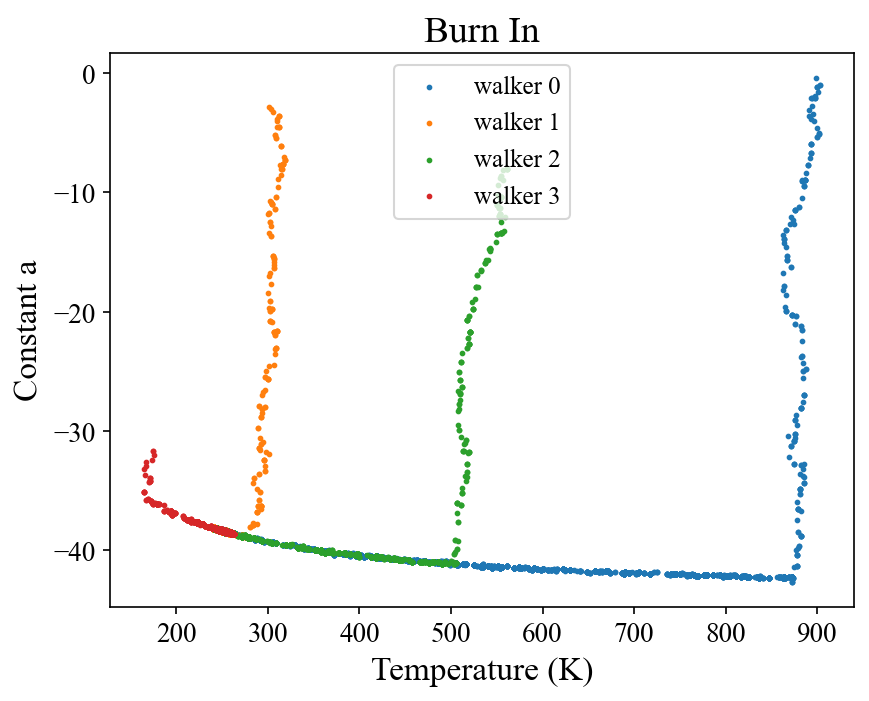

In [70]:
%matplotlib inline

for w in range(nwalkers):
    plt.scatter(thetachains[w][:,0], thetachains[w][:,1], s=3, label=f'walker {w}')
plt.title('Burn In')
plt.xlabel('Temperature (K)')
plt.ylabel('Constant a')
plt.legend()
plt.savefig('uniform_burnin.png')

In [71]:
for w in range(nwalkers):
    print(f"walker {w}: max loglike = {np.max(loglikechains[w]):.3f}")

walker 0: max loglike = -2.112
walker 1: max loglike = -2.112
walker 2: max loglike = -2.113
walker 3: max loglike = -2.112


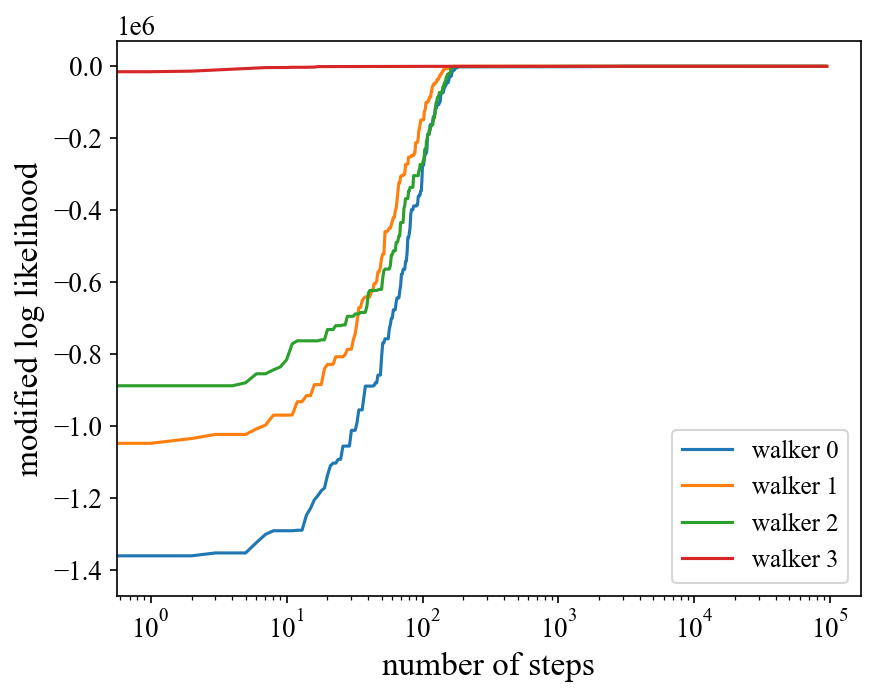

In [72]:
%matplotlib inline

for w in range(nwalkers):
    plt.plot(loglikechains[w], label=f'walker {w}')
plt.xscale('log')
plt.ylabel('modified log likelihood')
plt.xlabel('number of steps')
plt.legend()
plt.show()

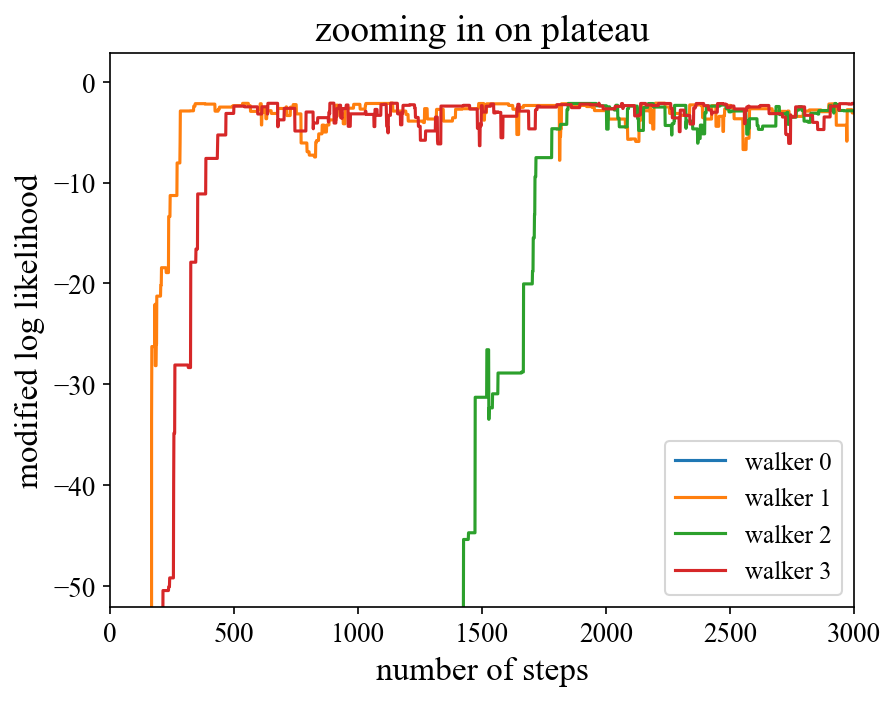

In [73]:
%matplotlib inline

best_loglike = max(np.max(L) for L in loglikechains)

for w in range(nwalkers):
    plt.plot(loglikechains[w], label=f'walker {w}')
plt.ylim(best_loglike - 50, best_loglike + 5)
plt.xlim(0, 3000)
plt.title('zooming in on plateau')
plt.ylabel('modified log likelihood')
plt.xlabel('number of steps')
plt.legend()
plt.show()

In [74]:
def find_burnin(loglikechain):
    # reference level: median log-likelihood of the second half of the chain
    ref = np.median(loglikechain[len(loglikechain) // 2:])
    # first step at which the chain reaches that level
    return int(np.argmax(loglikechain >= ref))

per-walker burn-in: [3197, 337, 1847, 499]  ->  using burnj = 3197


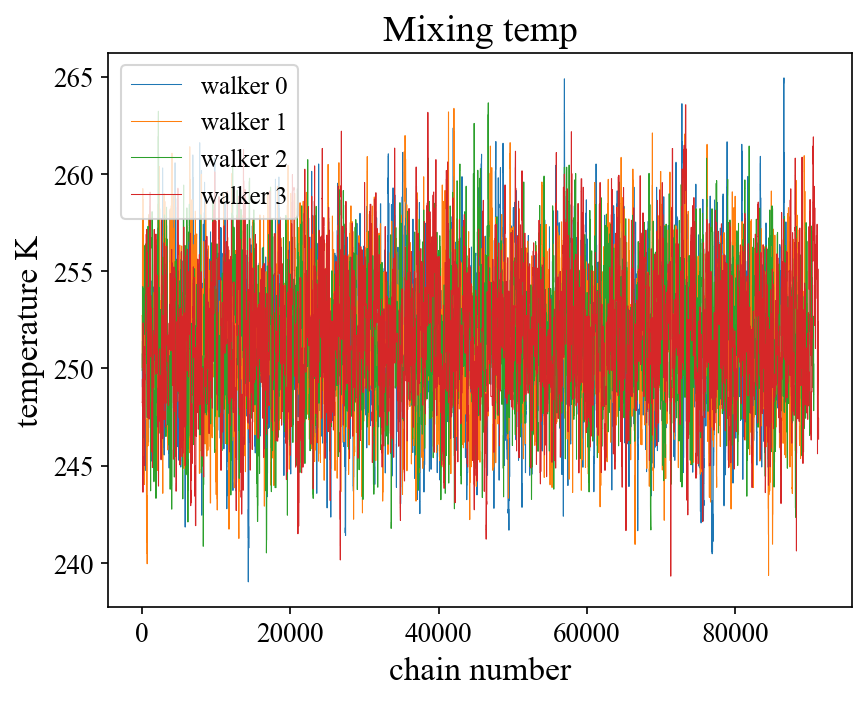

In [75]:
%matplotlib inline
# temperature mixing
burnjs = [find_burnin(L) for L in loglikechains]
burnj = max(burnjs)
print(f"per-walker burn-in: {burnjs}  ->  using burnj = {burnj}")
for w in range(nwalkers):
    plt.plot(thetachains[w][burnj:,0], lw=0.5, label=f'walker {w}')
plt.title('Mixing temp')
plt.xlabel('chain number')
plt.ylabel('temperature K')
plt.legend()
plt.show()

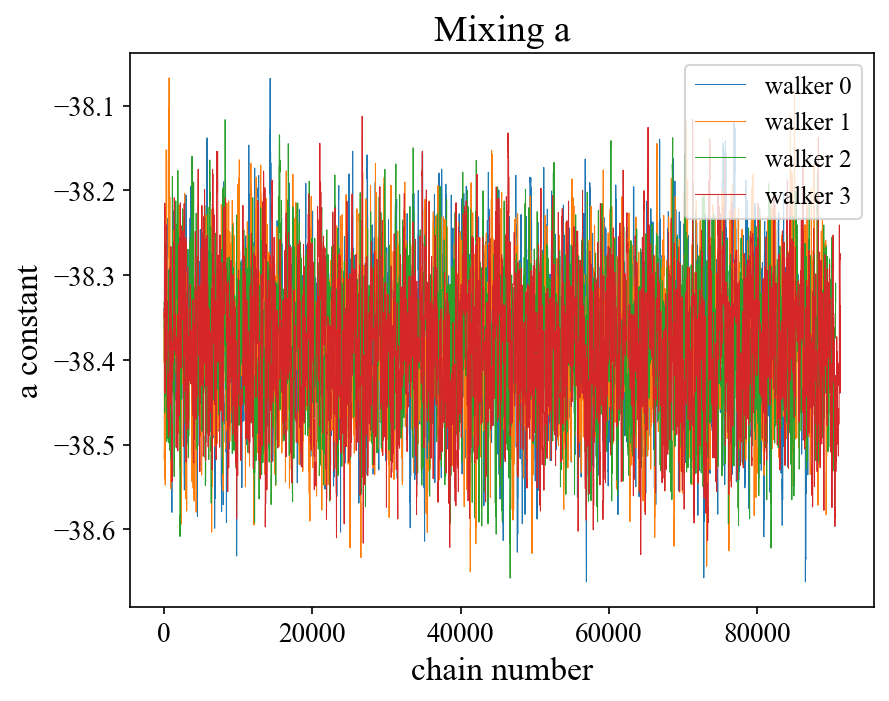

In [87]:
%matplotlib inline
# a constant mixing
burnj = max(burnjs)
for w in range(nwalkers):
    plt.plot(thetachains[w][burnj:,1], lw=0.5, label=f'walker {w}')
plt.title('Mixing a')
plt.xlabel('chain number')
plt.ylabel('a constant')
plt.legend()
plt.show()

In [88]:
# check the walkers agree with each other (Gelman-Rubin)
m = min(len(chain) for chain in thetachains) - burnj

for i, name in enumerate(['temperature', 'a']):
    x = np.array([chain[burnj:burnj+m, i] for chain in thetachains])   # shape (nwalkers, m)
    W = np.mean(np.var(x, axis=1, ddof=1))        # variance within each walker
    B = m * np.var(np.mean(x, axis=1), ddof=1)    # variance between the walkers
    Rhat = np.sqrt(((m - 1) / m * W + B / m) / W)
    print(f"{name}: R-hat = {Rhat:.3f}")

temperature: R-hat = 1.001
a: R-hat = 1.001


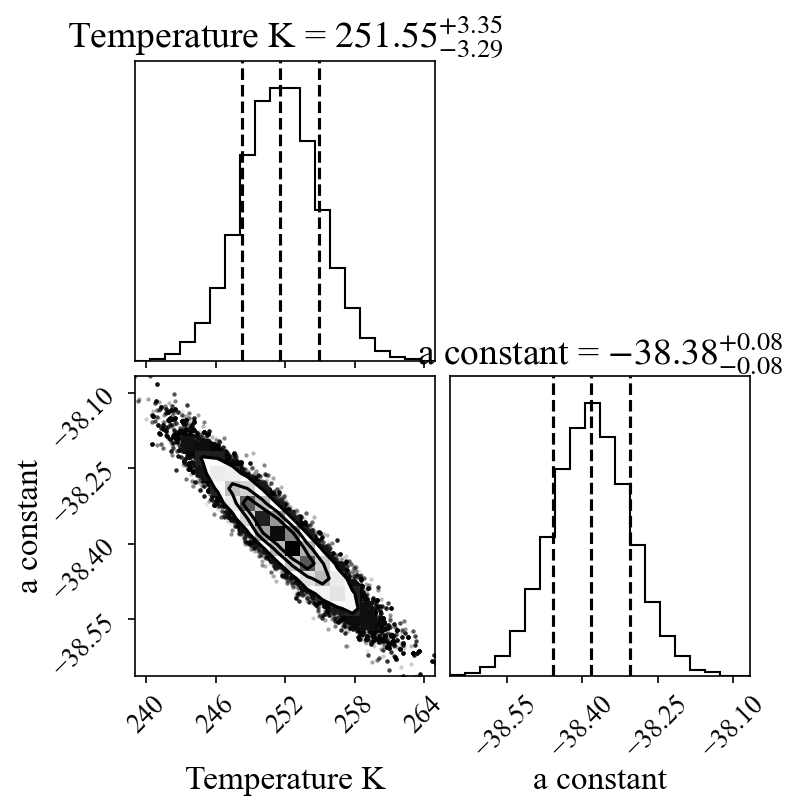

In [89]:
import corner

# combine all the walkers, burn-in removed from each one
samples = np.vstack([chain[burnj:] for chain in thetachains])
fig = corner.corner(
    samples,
    labels=['Temperature K','a constant'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True
)
plt.show()

chi2 = 3.86


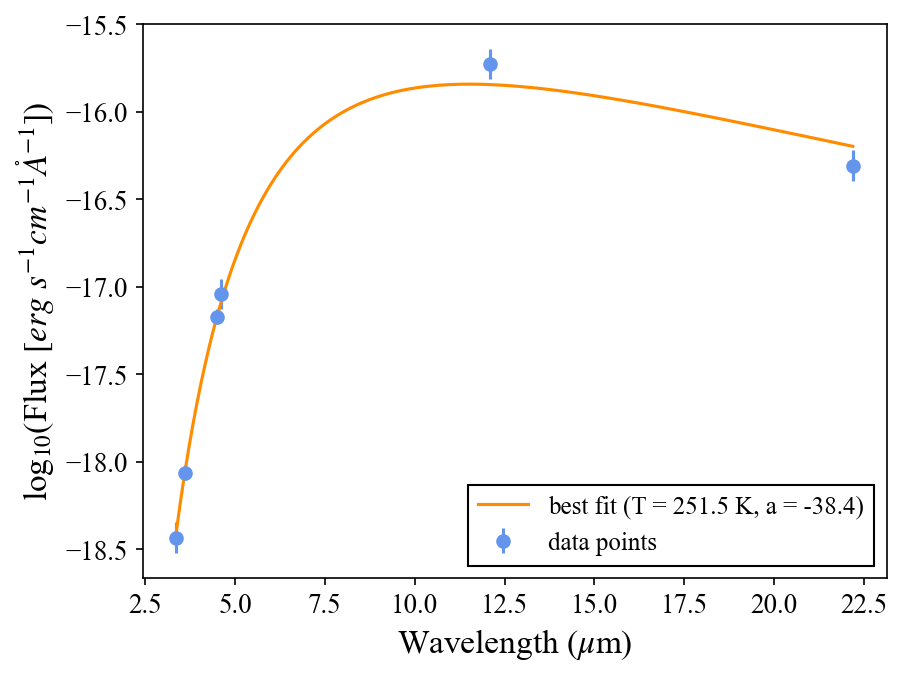

In [93]:
%matplotlib inline

# best fit = highest loglike sample from all the walkers
plt.errorbar(lam, logf, yerr=logf_err, fmt='o', color='cornflowerblue', label='data points')
plt.plot(lam_grid, blackbody_model(lam_grid, T_best, a_best), color='darkorange', label=f'best fit (T = {T_best:.1f} K, a = {a_best:.1f})')
plt.xlabel(r'Wavelength ($\mu$m)')
plt.ylabel(r'log$_{10}$(Flux [$erg\ s^{-1} cm^{-1} \mathring{A}^{-1}$])')
plt.legend(frameon=True, fancybox=False, edgecolor='black', framealpha=1, loc='lower right')
plt.savefig('uniformbest.png')

print(f"chi2 = {chi2(lam, logf, logf_err, [T_best, a_best]):.2f}")

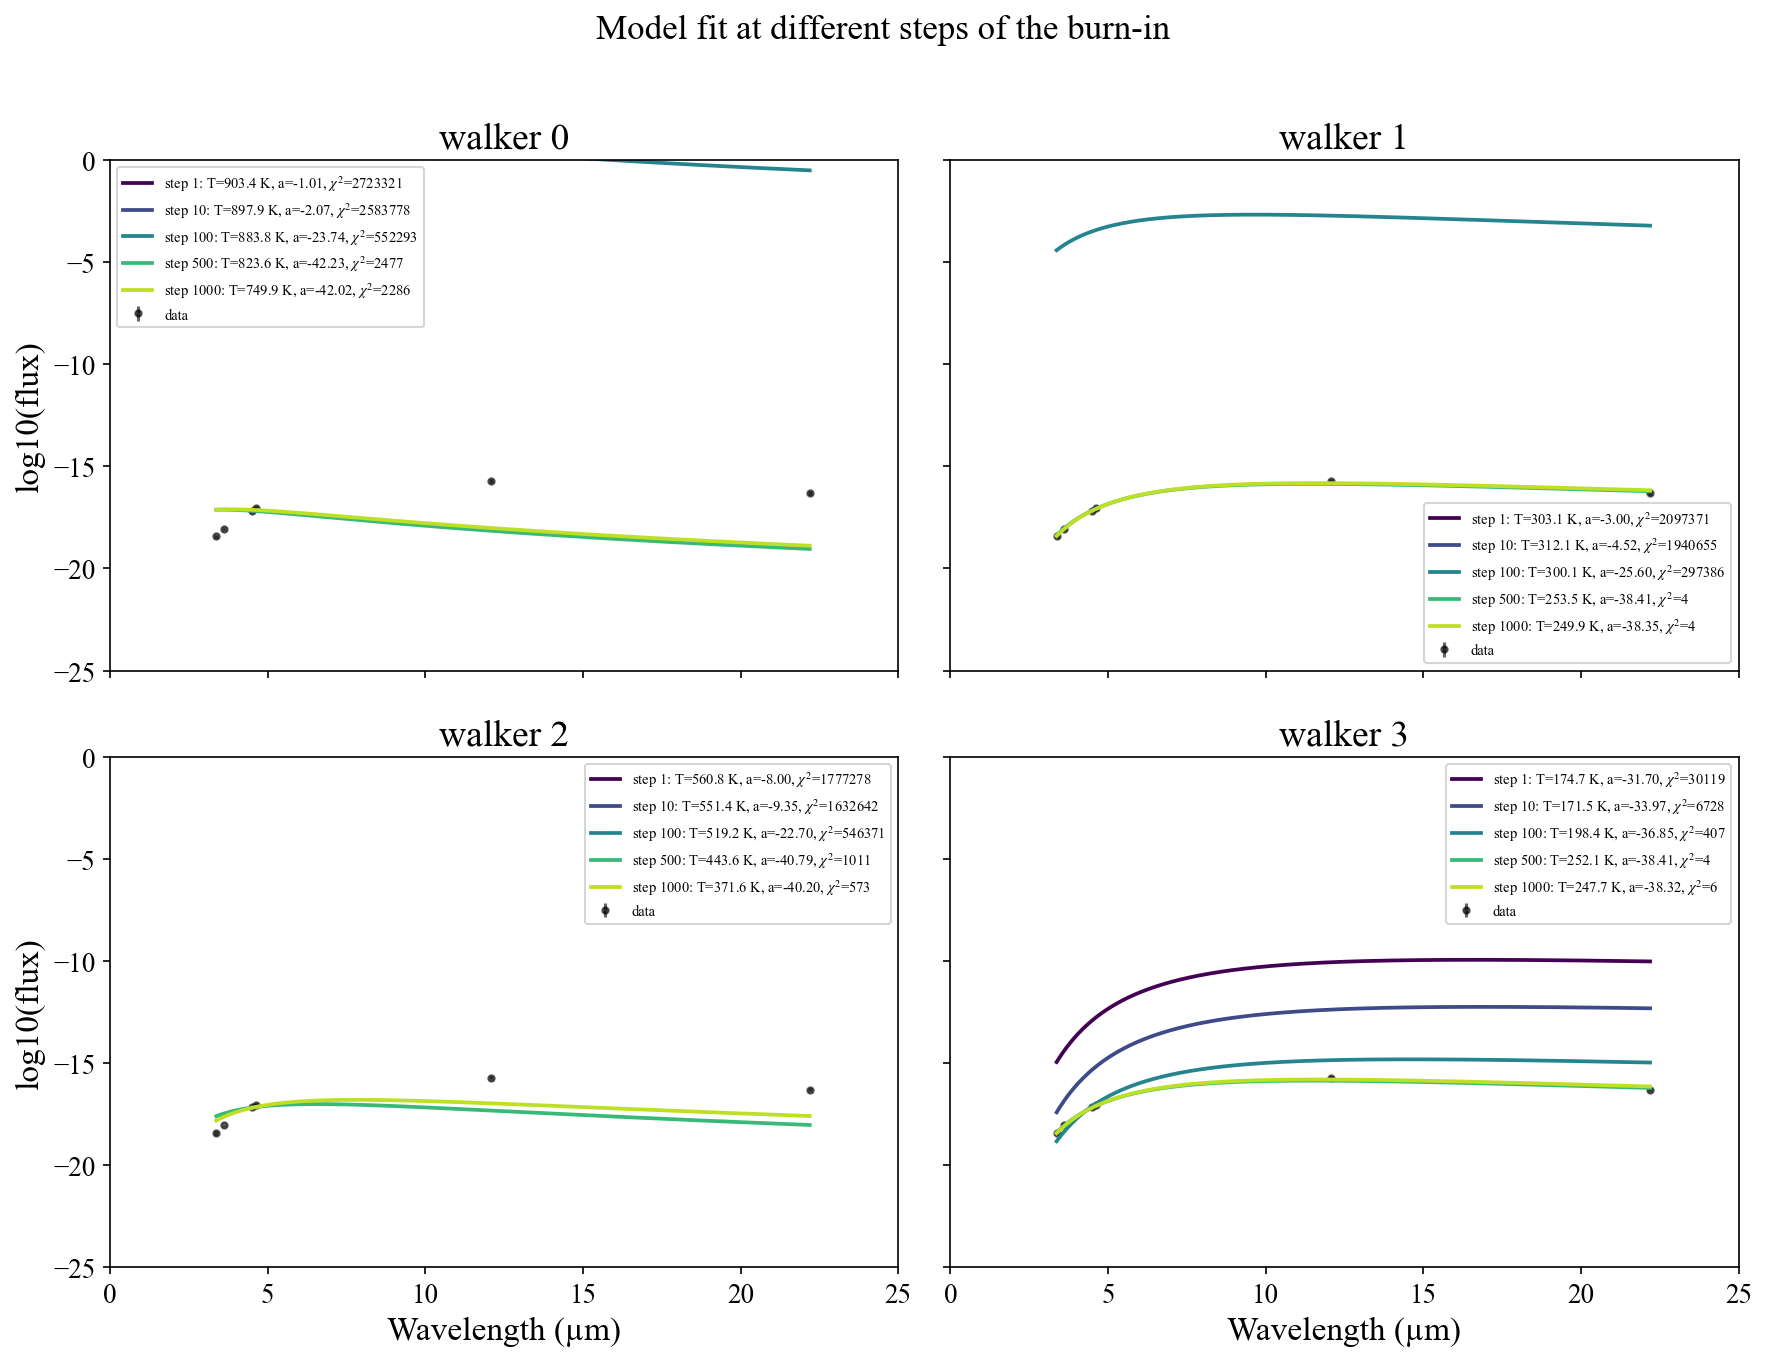

In [86]:
%matplotlib inline

steps = [1, 10, 100, 500, 1000]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(steps)))

lam_grid = np.linspace(lam.min(), lam.max(), 500)

ncols = 2
nrows = int(np.ceil(nwalkers / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
                         sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()

for w in range(nwalkers):
    ax = axes[w]
    ax.errorbar(lam, logf, yerr=logf_err, fmt='o', color='k', ms=3, alpha=0.6,
                label='data', zorder=1)

    for step, col in zip(steps, colors):
        theta_s = thetachains[w][step]
        T_s, a_s = theta_s
        chi2_s = chi2(lam, logf, logf_err, theta_s)
        with np.errstate(over='ignore', divide='ignore'):
            model = blackbody_model(lam_grid, T_s, a_s)
        ax.plot(lam_grid, model, color=col, lw=1.8, zorder=2,
                label=f'step {step}: T={T_s:.1f} K, a={a_s:.2f}, $\\chi^2$={chi2_s:.0f}')

    ax.set_ylim(logf.min() - 1, logf.max() + 1)
    ax.set_title(f'walker {w}')
    ax.legend(fontsize=7)

# hide any unused panels and label the outer axes
for ax in axes[nwalkers:]:
    ax.set_visible(False)
for ax in axes[-ncols:]:
    ax.set_xlabel('Wavelength (µm)')
    ax.set_xlim(0,25)
for ax in axes[::ncols]:
    ax.set_ylabel('log10(flux)')
    ax.set_ylim(-25,0)

fig.suptitle('Model fit at different steps of the burn-in', y=1.01)
plt.tight_layout()
plt.show()